# 00 · Set up and understand the hedging study

**Study question:** How much risk reduction does more frequent hedging buy, and when do transaction costs or incorrect hedge-volatility assumptions change that comparison?

This completed setup notebook values three **short European calls**, calculates their opening exposures, generates joint stock-price histories, checks the simulated marginal behavior and correlations, and records the run inputs. Hedge trading and cash-account P&L begin in notebook 01.

JPM, PNC and GS are labels. All inputs are illustrative and are not calibrated market observations. Stock paths follow correlated GBM under the risk-neutral measure Q, with zero dividends and constant rates/volatilities.

Choose a Python environment with `requirements-harness.txt` and **Run All from a fresh kernel**. Both the project root and `notebooks` work as kernel starting directories. Markdown cells explain the purpose, units and interpretation of each calculation.

## The route through the notebook

| Stage | Purpose | Main functions/tools |
|---|---|---|
| 1. Connect to the project | Locate local modules and import packages | `Path`, `sys.path` |
| 2. Define the study | Keep each security's inputs and each correlation pair named | `option_portfolio`, `scenario` |
| 3. Inspect assumptions | Read units and check name alignment | `pandas.DataFrame`, `.loc` |
| 4. Value calls and inspect exposures | Price options, calculate Greeks and size the initial delta offset | `bs_d1_d2`, `bs_price`, `bs_payoff`, `bs_greeks` |
| 5–7. Generate and inspect paths | Simulate exact correlated Q-GBM and plot samples | `Book`, `simulate_paths`, matplotlib |
| 8–9. Check the simulation | Inspect discounted means, volatility and return correlations | NumPy reductions and log returns |
| 10. Record the run | Capture actual inputs, versions and source hashes | `provenance`, `json.dumps` |

The named dictionaries below are the source of inputs for this notebook. The conversion to ordered arrays happens explicitly at the simulator boundary, using the same asset order on every axis. The shared JSON defaults are not reloaded over your dictionaries.

## 1 · Connect the notebook to the project

Locate the project root, add it to Python's module search path, and import the analysis packages. Imports use saved `.py` files; rerunning the Black–Scholes import cell reloads edits made to that module.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd()
while not (ROOT / 'src' / 'hedging_harness').is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
assert (ROOT / 'src' / 'hedging_harness').is_dir(), 'Open this notebook inside the repository.'
sys.path.insert(0, str(ROOT / 'src'))
from IPython.display import display
from hedging_harness.configuration import defaults, notebook_controls
from hedging_harness.notebook_support import verify_frozen_overlay, historical_root, historical_path


In [2]:
_controls = notebook_controls('00_study_setup')
from pathlib import Path
import sys
import json
from hashlib import sha256

import numpy as np
import pandas as pandas
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / "src" / "BlackScholes_Functions").is_dir():
    ROOT = ROOT.parent
assert (ROOT / "src" / "BlackScholes_Functions").is_dir(), f"Wrong project root: {ROOT}"

display(ROOT)



PosixPath('/Users/saireddivari/MonteCarloEvaluations')

## 2 · Define the study with named inputs

Each security owns its contract and pricing inputs. The scenario separately owns path volatilities and named correlation pairs. Rates and volatilities are annual decimals; time is converted using the specified trading calendar. The setup assumes short calls with $100,000 initial underlying notional per name.

In [3]:
from hedging_harness.study import load_named_inputs
option_portfolio, scenario, shared_config = load_named_inputs(ROOT / 'config/illustrative_study.json')

# scenario loaded from the same versioned study inputs


display(option_portfolio['GS']['pricing_vol'])
display(scenario['correlations'][("JPM","GS")])
display(list(option_portfolio)) #calling list on a dictionary gives you the first level keys in a list
display(list(option_portfolio['GS'])) #you can then drill down into the next level keys in a list




0.26

0.7

['JPM', 'PNC', 'GS']

['spot',
 'strike',
 'notional',
 'pricing_vol',
 'days_to_expiration',
 'days_in_trading_year',
 'risk_free_rate']

## 3 · Inspect assumptions and correlations

Build the correlation matrix with security labels on both axes. Self-correlations are 1, and each named pair fills both mirrored entries. The checks reject unknown names, missing or repeated pairs, invalid bounds and a matrix that is not positive semidefinite.

In the assumptions table, `call units = notional / spot`, and `time_to_expiration_years = days_to_expiration / days_in_trading_year`. At the baseline, each name has 1,000 call units and a maturity of 0.25 years. These quantities are not exchange contract counts.

In [4]:
option_underlyings = list(option_portfolio)
assert set(scenario["path_vols"]) == set(option_underlyings), "Path-volatility names must match the option portfolio names."

# Keep labels attached while constructing the numerical correlation matrix.
correlation_matrix = pandas.DataFrame(
    np.eye(len(option_underlyings)),
    index=option_underlyings,
    columns=option_underlyings,
)
seen_pairs = set() #create an empty set of pairs of names --> sets store values without any duplicates. allows us to loop through scenario[correlations] however many names there are, and ensure we dont get the same pairs correlation twice
for (name_a, name_b), value in scenario["correlations"].items(): #name a and name b are the 'tickers' in the tuple, the value is the correlation
    assert name_a in option_portfolio and name_b in option_portfolio, "Unknown correlation name." #making sure that the 'tickers' are in the 3 name portfolio
    assert name_a != name_b, "Self-correlations are already set to 1." #ensures that we are not comparing the same name to the same name
    assert np.isfinite(value) and -1 <= value <= 1, "Invalid correlation value." #if the correlation between a two security pair is <|1| then thats incorrect 
    pair = frozenset((name_a, name_b)) #loops through the 3 tuples/name-pairs in scenario[correlations], ensures that they are stable and fixed moving fwd.  
    assert pair not in seen_pairs, "Specify each unordered correlation pair once." #if a pair is not in seen_pairs, then add that pair to the seen_pairs
    seen_pairs.add(pair) 
    correlation_matrix.loc[name_a, name_b] = value #name_a Row, name_B column, value = X
    correlation_matrix.loc[name_b, name_a] = value #name_B Row, name_A column, value = X >equivalency in pair correlation on both 'sides' of matrix

assert len(seen_pairs) == len(option_underlyings) * (len(option_underlyings) - 1) // 2, "Missing correlation pair." #quadratic rule for n-security portfolios. nxn corr matrix --> [n(n-1)]/2 off-diag corrs 
assert np.linalg.eigvalsh(correlation_matrix.to_numpy()).min() >= -1e-10, "Correlation must be positive semidefinite."
display(correlation_matrix)

assumptions = pandas.DataFrame.from_dict(option_portfolio, orient="index")
assumptions.index.name = "name"
assumptions["call units"] = assumptions["notional"] / assumptions["spot"]
assumptions["time_to_expiration_years"] = (
    assumptions["days_to_expiration"] / assumptions["days_in_trading_year"]
)
assumptions["path_vol"] = pandas.Series(scenario["path_vols"])
assert assumptions.index.tolist() == option_underlyings
assert not assumptions.isna().any().any(), "Missing or misaligned inputs."
display(assumptions)

import importlib
import BlackScholes_Functions.BlackScholes_D1D2_Price_Payoff_Greeks as bs

# Reload saved module edits when this cell is rerun in an existing kernel.
importlib.reload(bs)
from BlackScholes_Functions.BlackScholes_D1D2_Price_Payoff_Greeks import (
    bs_d1_d2, bs_price, bs_payoff, bs_greeks
)
from hedging_harness import Book, simulate_paths, provenance



,JPM,PNC,GS
JPM,1.00,0.65,0.70
PNC,0.65,1.00,0.55
GS,0.70,0.55,1.00


,spot,strike,notional,pricing_vol,days_to_expiration,days_in_trading_year,risk_free_rate,call units,time_to_expiration_years,path_vol
name,,,,,,,,,,
JPM,100.0,100.0,100000.0,0.22,63,252,0.04,1000.0,0.25,0.22
PNC,100.0,100.0,100000.0,0.28,63,252,0.04,1000.0,0.25,0.28
GS,100.0,100.0,100000.0,0.26,63,252,0.04,1000.0,0.25,0.26


## Black–Scholes calculations · three short calls

We hold **short European calls** on JPM, PNC and GS. Each function below uses the named security's spot, strike, annual rate, annual pricing volatility and maturity in years.

| Function | Purpose | Output |
|---|---|---|
| `bs_d1_d2(...)` | Calculate Black–Scholes intermediate quantities | `d1`, `d2` |
| `bs_price(..., kind="call")` | Value one long call unit today | Per-unit call price |
| `bs_payoff(ST, K, kind="call")` | Calculate one call unit's payoff at expiry | `max(ST - K, 0)` |
| `bs_greeks(..., kind="call")` | Calculate one long call unit's sensitivities | Delta, gamma, vega, theta and rho |

These functions describe one **long** call unit. A short unit's value, settlement cash flow and Greeks have the opposite signs. The `d1` and `d2` values themselves stay the same. We calculate per-unit results first, then scale by position quantities in section 4.

### Calculate d1, d2 and today's call prices

Loop through the named portfolio, read each option's inputs explicitly, and convert trading sessions to years. Store full precision and round only the displayed table.

`call_price` is the positive model price of one call unit. The short call's per-unit position value is its negative. A sale now at that price would receive the positive premium and create an equal-valued liability. For an already-existing position, the actual entry premium is a separate historical input.

In [5]:
OPTION_KIND = _controls['OPTION_KIND']
POSITION_SIGN = _controls['POSITION_SIGN']  # Pricing functions return long-call values; our positions are short.

valuation_rows = []

for name, option in option_portfolio.items():
    S = option["spot"]
    K = option["strike"]
    T = option["days_to_expiration"] / option["days_in_trading_year"]
    r = option["risk_free_rate"]
    sigma = option["pricing_vol"]

    d1, d2 = bs_d1_d2(S=S, K=K, T=T, r=r, sigma=sigma)
    price = bs_price(S=S, K=K, T=T, r=r, sigma=sigma, kind=OPTION_KIND)

    valuation_rows.append({
        "name": name,
        "maturity_years": T,
        "d1": d1,
        "d2": d2,
        "call_price": price,
        "short_value_per_unit": POSITION_SIGN * price,
    })

option_values = pandas.DataFrame(valuation_rows).set_index("name")
display(option_values.round(6))



,maturity_years,d1,d2,call_price,short_value_per_unit
name,,,,,
JPM,0.25,0.145909,0.035909,4.879844,-4.879844
PNC,0.25,0.141429,0.001429,6.064514,-6.064514
GS,0.25,0.141923,0.011923,5.669552,-5.669552


### Calculate per-unit Greeks

`bs_greeks(...)` returns Greeks for **one long call unit**; multiplying by `-1` gives **one short call unit**.

- Delta is option-price change per $1 stock-price increase.
- Gamma is the change in delta per $1 stock-price increase.
- Vega is per 1.00 change in annual volatility. Multiply by `0.01` for a one percentage-point increase.
- Theta is calendar-time decay per year, holding other inputs fixed.
- Rho is per 1.00 change in the annual interest rate. Multiply by `0.01` for a one percentage-point increase.

The following tables retain these raw units. Section 4 scales them to the actual positions and reports vega/rho per percentage point and theta per trading session.

In [6]:
greek_rows = [] #empty set 

for name, option in option_portfolio.items(): #call the bs_greeks function from BlackScholes_functions, define the input variables as constants across all names and derive values for each greek
    greeks = bs_greeks(
        S=option["spot"],
        K=option["strike"],
        T=option["days_to_expiration"] / option["days_in_trading_year"],
        r=option["risk_free_rate"],
        sigma=option["pricing_vol"],
        kind=OPTION_KIND,
    )
    greek_rows.append({"name": name, **greeks}) #for each name in the option portfolio, create a row indexed by name
                                                #unfurl the greeks associated with that name into a dictionary containing the name, insert every key/va;lue pair from greeks for that name  

display(greek_rows) #this is now a set of 3 dictionaries - one for each name and its greeks. 
per_unit_greeks = pandas.DataFrame(greek_rows).set_index("name") #turn it into a dataframe
short_call_greeks = POSITION_SIGN * per_unit_greeks

print("One long call unit — raw Greek units:")
display(per_unit_greeks.round(6))
print("One short call unit — raw Greek units:")
display(short_call_greeks.round(6))



[{'name': 'JPM',
  'delta': np.float64(0.5580034225545027),
  'gamma': np.float64(0.035883469921056996),
  'vega': np.float64(19.735908456581345),
  'theta': np.float64(-10.720619646232471),
  'rho': np.float64(12.730124533354232)},
 {'name': 'PNC',
  'delta': np.float64(0.5562343078115392),
  'gamma': np.float64(0.028212309668125105),
  'vega': np.float64(19.748616767687576),
  'theta': np.float64(-13.041582043712195),
  'rho': np.float64(12.38972908629469)},
 {'name': 'GS',
  'delta': np.float64(0.5564296169638213),
  'gamma': np.float64(0.03038035882839975),
  'vega': np.float64(19.747233238459838),
  'theta': np.float64(-12.267497666561793),
  'rho': np.float64(12.49335239101673)}]

One long call unit — raw Greek units:


,delta,gamma,vega,theta,rho
name,,,,,
JPM,0.558003,0.035883,19.735908,-10.720620,12.730125
PNC,0.556234,0.028212,19.748617,-13.041582,12.389729
GS,0.556430,0.030380,19.747233,-12.267498,12.493352


One short call unit — raw Greek units:


,delta,gamma,vega,theta,rho
name,,,,,
JPM,-0.558003,-0.035883,-19.735908,10.720620,-12.730125
PNC,-0.556234,-0.028212,-19.748617,13.041582,-12.389729
GS,-0.556430,-0.030380,-19.747233,12.267498,-12.493352


### Calculate payoffs across example expiry prices

A payoff requires an **expiry stock price** `ST`. Actual terminal prices will come from the later GBM simulation. For now, use an editable illustrative grid from 70 to 130 for each name. These are hypothetical scenarios, not forecasts or simulated paths.

`bs_payoff(...)` returns the amount received by a long call holder. One short call unit pays that amount, giving a negative settlement cash flow. These are expiry payoffs, **not P&L**: they exclude the entry premium, financing, stock hedging and transaction costs.

**Checkpoint:** below or at strike, call payoff is zero. Above strike, the short settlement cash flow becomes increasingly negative.

In [7]:
terminal_spot_grid = np.array([70.0, 80.0, 90.0, 100.0, 110.0, 120.0, 130.0])
payoff_tables = {}

for name, option in option_portfolio.items():
    payoff_per_unit = bs_payoff(
        ST=terminal_spot_grid, K=option["strike"], kind=OPTION_KIND
    )
    payoff_tables[name] = pandas.DataFrame({
        "terminal_spot": terminal_spot_grid,
        "call_payoff_per_unit": payoff_per_unit,
        "short_payoff_per_unit": POSITION_SIGN * payoff_per_unit,
    }).set_index("terminal_spot")

payoff_scenarios = pandas.concat(payoff_tables, names=["name", "terminal_spot"])
display(payoff_scenarios.round(4))


#we have already sold the calls (short call) with  strikes at 100, we have received a premium for that
#we do a basic grid of terminal stock prices +/- 30% of current spot/strike (equivalent) so from $70 to $130
#payoff if terminal price is below $100 for us is zero, we have received our 'payoff' from the premium selling the options
#as terminal price increases above strike price, payoff is linearly worse 
#netPNL = premium received + payoff paid. so if its OOM, just premium received. if its IIM, can still be positive PNL if premium > payoff paid. 



call_payoff_per_unit  short_payoff_per_unit
name terminal_spot                                             
JPM  70.0                            0.0                   -0.0
     80.0                            0.0                   -0.0
     90.0                            0.0                   -0.0
     100.0                           0.0                   -0.0
     110.0                          10.0                  -10.0
     120.0                          20.0                  -20.0
     130.0                          30.0                  -30.0
PNC  70.0                            0.0                   -0.0
     80.0                            0.0                   -0.0
     90.0                            0.0                   -0.0
     100.0                           0.0                   -0.0
     110.0                          10.0                  -10.0
     120.0                          20.0                  -20.0
     130.0                          30.0                  -30.0
GS   70.0                            0.0                   -0.0
     80.0                            0.0                   -0.0
     90.0                            0.0                   -0.0
     100.0                           0.0                   -0.0
     110.0                          10.0                  -10.0
     120.0                          20.0                  -20.0
     130.0                          30.0                  -30.0

## 4 · Calculate the opening position exposures

Combine the assumptions, prices and **long-call per-unit Greeks** side by side with `pandas.concat(..., axis=1)`. Rows align by security name; `verify_integrity=True` catches duplicate column labels.

For a short position with positive call-unit magnitude $N$:

| Column | Calculation | Interpretation |
|---|---|---|
| `initial_premium` | $NC$ | Model cash received if sold now; an equal liability is created |
| `hedge_shares` | $N\Delta$ | Positive stock holding offsetting short-call delta |
| `option_dollar_delta` | $-N\Delta S_0$ | Multiply by 0.01 for first-order P&L on a +1% stock move |
| `option_gamma_pnl_for_1pct_move` | $-\frac12N\Gamma(0.01S_0)^2$ | Second-order contribution for a 1% stock move |
| `option_vega_per_vol_point` | $-N\nu\times0.01$ | P&L sensitivity to a one percentage-point pricing-volatility increase |

`initial_premium` is **not an expiry payoff**. For an existing trade, the historical premium must be supplied separately to calculate P&L since entry. These are share-equivalent call units, with no exchange contract multiplier or lot rounding.

The stock holding offsets initial delta only. Negative gamma and vega remain. Greeks for different stocks cannot be treated as interchangeable share hedges.

In [8]:
combined_options_table = pandas.concat(
    [
        assumptions,
        option_values[["d1", "d2", "call_price", "short_value_per_unit"]],
        per_unit_greeks,
    ],
    axis=1,
    verify_integrity=True,
)
assert combined_options_table.index.tolist() == option_underlyings
assert not combined_options_table.isna().any().any()

units = combined_options_table["call units"]
spot = combined_options_table["spot"]
combined_options_table["signed_call_units"] = POSITION_SIGN * units

#we calculate the "initial premium" - value of the option position if we sold it at market price/BS price, because it 
#tells us how much cash we can get from the options, and the cash is then used to fund the stock hedge against the short call position 
combined_options_table["initial_premium"] = units * combined_options_table["call_price"] #premium you can get for selling the options
combined_options_table["option_value"] = -combined_options_table["initial_premium"] #but we are short the options, so the option value is -1 * the option premium

combined_options_table["option_delta_shares"] = POSITION_SIGN * units * combined_options_table["delta"] # option position total $ movement for $1 stock price
combined_options_table["equity_hedge_shares"] = -combined_options_table["option_delta_shares"]

#^option_delta_shares .... option units * delta = $ delta shares. for 1000 units, and .56 delta, $1 movement in price reults in -$560 loss in option position
#equity_hedge_shares .... to hedge against that option delta, you would need 560 shares of stock (each moves $1 up cancelling the option position move)

display(combined_options_table)
#book_monetized_delta = call units * option delta * underlying stock price  
combined_options_table["option_dollar_delta"] = combined_options_table["option_delta_shares"] * spot

#book_mon_gamma1% = 0.5 * call units * gamma * .01(spot price)^2 (the gamma pnl contribution when underlying moves)
combined_options_table["option_gamma_pnl_for_1pct_move"] = (
    POSITION_SIGN * 0.5 * units * combined_options_table["gamma"] * (0.01 * spot) ** 2
)

#daily_book_mon_vega1% = call units * vega * .01 (daily vega pnl contribution from .01 shift in vol)
combined_options_table["option_vega_per_vol_point"] = (
    POSITION_SIGN * units * combined_options_table["vega"] * 0.01
)

#daily_book_mon_theta = call units * theta / 252 (daily theta pnl contribution from 1 day elapsed )
combined_options_table["option_theta_per_session"] = (
    POSITION_SIGN * units * combined_options_table["theta"]
    / combined_options_table["days_in_trading_year"]
)

#daily_book_mon_rho (daily rho contribution to daily pnl )
combined_options_table["option_rho_per_rate_point"] = (
    POSITION_SIGN * units * combined_options_table["rho"] * 0.01
)

##delta-neutral (in theory) --> because you are long the exact amount of equity shares to offset short delta from options
## however - option has Gamma - the change in the Delta of the option based on the change in stock price / time movement . so option delta continues to move, and not 
#linerly with equity hedge amount, and therefore you are not perfectly delta hedged until/unless you rebalance your optionshare holding
combined_options_table["net_delta_after_hedge"] = (
    combined_options_table["option_delta_shares"] + combined_options_table["equity_hedge_shares"]
)

exposure_columns = [
    "call units", "initial_premium", "equity_hedge_shares", "option_dollar_delta",
    "option_gamma_pnl_for_1pct_move", "option_vega_per_vol_point",
    "option_theta_per_session", "option_rho_per_rate_point", "net_delta_after_hedge",
]
exposures = combined_options_table[exposure_columns].copy()
position_greeks = per_unit_greeks.mul(combined_options_table["signed_call_units"], axis="index")

np.testing.assert_allclose(combined_options_table["net_delta_after_hedge"], 0.0, atol=1e-12)
np.testing.assert_allclose(
    combined_options_table["option_value"] + combined_options_table["initial_premium"], 0.0
)
assert (position_greeks[["delta", "gamma", "vega"]] < 0).all().all() #delta/gamma/vega should be negative because we are short the call
assert (exposures["equity_hedge_shares"] > 0).all()
display(exposures.round(4))
print("Short-call signs, premium/liability and initial delta-offset checks passed.")

# Reproducible experiment controls. Edit these for a different run.


,spot,strike,notional,pricing_vol,days_to_expiration,days_in_trading_year,risk_free_rate,call units,time_to_expiration_years,path_vol,...,delta,gamma,vega,theta,rho,signed_call_units,initial_premium,option_value,option_delta_shares,equity_hedge_shares
name,,,,,,,,,,,,,,,,,,,,,
JPM,100.0,100.0,100000.0,0.22,63,252,0.04,1000.0,0.25,0.22,...,0.558003,0.035883,19.735908,-10.720620,12.730125,-1000.0,4879.844122,-4879.844122,-558.003423,558.003423
PNC,100.0,100.0,100000.0,0.28,63,252,0.04,1000.0,0.25,0.28,...,0.556234,0.028212,19.748617,-13.041582,12.389729,-1000.0,6064.514436,-6064.514436,-556.234308,556.234308
GS,100.0,100.0,100000.0,0.26,63,252,0.04,1000.0,0.25,0.26,...,0.556430,0.030380,19.747233,-12.267498,12.493352,-1000.0,5669.552132,-5669.552132,-556.429617,556.429617


,call units,initial_premium,equity_hedge_shares,option_dollar_delta,option_gamma_pnl_for_1pct_move,option_vega_per_vol_point,option_theta_per_session,option_rho_per_rate_point,net_delta_after_hedge
name,,,,,,,,,
JPM,1000.0,4879.8441,558.0034,-55800.3423,-17.9417,-197.3591,42.5421,-127.3012,0.0
PNC,1000.0,6064.5144,556.2343,-55623.4308,-14.1062,-197.4862,51.7523,-123.8973,0.0
GS,1000.0,5669.5521,556.4296,-55642.9617,-15.1902,-197.4723,48.6805,-124.9335,0.0


Short-call signs, premium/liability and initial delta-offset checks passed.


## 5 · Understand the model before calling the simulator

**Purpose:** know what the simulated paths represent.

For each asset $i$, this study assumes

$$
dS_t^{(i)} = r S_t^{(i)}\,dt + \sigma_i S_t^{(i)}\,dW_t^{(i),\mathbb{Q}},
\qquad dW_t^{(i),\mathbb{Q}}dW_t^{(j),\mathbb{Q}} = \rho_{ij}\,dt.
$$

The exact update over one session is

$$
S_{t+\Delta t}^{(i)} = S_t^{(i)}\exp\!\left[
\left(r-\frac{1}{2}\sigma_i^2\right)\Delta t
+ \sigma_i\sqrt{\Delta t}\,Z_i\right],
\qquad \Delta t=1/252.
$$

The standard-normal shocks $Z_i$ are correlated across names within each session. Increments across sessions are independent in this model. The simulator uses `scenario['path_vols']` for $\sigma_i$.

**Write a short explanation below:**

1. What does using $\mathbb{Q}$ imply about the drift, and why is it not a historical expected-return estimate?
2. Why does the exponential update contain the $-\sigma_i^2/2$ term?
3. What should changing correlation affect? What happens to a standalone Black–Scholes call value if its own marginal inputs stay fixed?

**Checkpoint:** you can distinguish the drift of price from the drift of log price. You can also distinguish an exact GBM price update from the discrete rebalancing of a hedge.

**Model interpretation**

Under Q, zero-dividend stock prices have drift equal to the financing rate $r$. This is a pricing-measure simulation, rather than an estimate of historical expected stock returns. The log-price drift is $r-\sigma^2/2$; the correction makes the exponential's expected growth agree with $e^{r\Delta t}$.

Correlation links the stocks' same-session shocks and changes joint portfolio outcomes. With each stock's own inputs held fixed, changing correlation leaves its standalone Black–Scholes price unchanged. Finite-sample marginal estimates can nevertheless move because the generated joint shocks change.

The price update is exact for constant-parameter GBM. Any hedge introduced in later notebooks still trades only at discrete observation times.

## 6 · Generate joint stock-price histories

The source inputs stay in your named dictionaries. The shared simulator expects a `Book` and numerical arrays, so the following cell converts them using `option_underlyings` as the single asset order. Correlation rows and columns are explicitly selected in that order.

This simulator uses a common expiry, trading calendar and rate. The cell checks that these agree across names before constructing the book. `pricing_vols` remain in the book; the **path volatilities** are supplied separately to `simulate_paths(...)`.

With 5,000 paths, 63 sessions and three names, the output shape is `(5000, 64, 3)`: **path, date including inception, asset**. The assertions verify shape, starting prices, positivity and finite values.

In [9]:
N_PATHS = _controls['N_PATHS']
SEED = _controls['SEED']

for field in ("days_to_expiration", "days_in_trading_year", "risk_free_rate"):
    assert assumptions[field].nunique() == 1, f"The current simulator requires one common {field}."

first_option = option_portfolio[option_underlyings[0]]

book = Book(
    names=tuple(option_underlyings),
    spots=tuple(option_portfolio[name]["spot"] for name in option_underlyings),
    strikes=tuple(option_portfolio[name]["strike"] for name in option_underlyings),
    notionals=tuple(option_portfolio[name]["notional"] for name in option_underlyings),
    pricing_vols=tuple(option_portfolio[name]["pricing_vol"] for name in option_underlyings),
    steps=first_option["days_to_expiration"],
    sessions_per_year=first_option["days_in_trading_year"],
    rate=first_option["risk_free_rate"],
)
simulation_scenario = {
    "path_vols": [scenario["path_vols"][name] for name in option_underlyings],
    "correlation": correlation_matrix.loc[option_underlyings, option_underlyings].to_numpy().tolist(),
}
paths = simulate_paths(book, **simulation_scenario, n_paths=N_PATHS, seed=SEED)

assert paths.shape == (N_PATHS, book.steps + 1, len(book.names))
assert np.isfinite(paths).all() and (paths > 0).all()
np.testing.assert_allclose(paths[:, 0, :], np.broadcast_to(book.spots, (N_PATHS, len(book.names))))
print(f"Asset order: {book.names}")
print(f"Paths shape: {paths.shape} — (path, date including inception, asset)")
print(f"Seed: {SEED}; maturity: {book.maturity:.2f} years; rate: {book.rate:.1%}")



Asset order: ('JPM', 'PNC', 'GS')
Paths shape: (5000, 64, 3) — (path, date including inception, asset)
Seed: 20261105; maturity: 0.25 years; rate: 4.0%


## 7 · Plot sample joint paths

Plot the first 12 simulated histories for each stock, keeping the same simulated path numbers across panels. Transposing the selected array places dates on the first axis, allowing matplotlib to draw one line per path.

Every line begins at its configured spot. A common price scale makes dispersion easier to compare. Twelve example histories provide a visual check; the full simulated sample supplies the statistical diagnostics below.

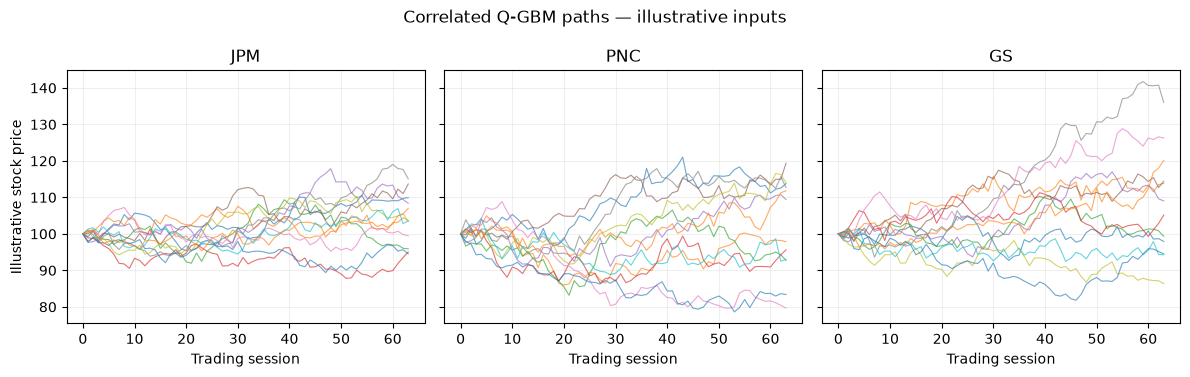

In [10]:
sample_count = min(12, N_PATHS)
sessions = np.arange(book.steps + 1)
fig, axes = plt.subplots(1, len(book.names), figsize=(12, 3.8), sharey=True, squeeze=False)
for asset_index, name in enumerate(book.names):
    ax = axes[0, asset_index]
    ax.plot(sessions, paths[:sample_count, :, asset_index].T, alpha=0.65, linewidth=0.8)
    ax.set(title=name, xlabel="Trading session")
    ax.grid(alpha=0.2)
axes[0, 0].set_ylabel("Illustrative stock price")
fig.suptitle("Correlated Q-GBM paths — illustrative inputs")
fig.tight_layout()
plt.show()



## 8 · Check the discounted stock mean

**Purpose:** test a consequence of the zero-dividend Q model using Monte Carlo uncertainty.

Under these assumptions,

$$
\mathbb{E}^{\mathbb{Q}}[e^{-rT}S_T^{(i)}]=S_0^{(i)}.
$$

**Calculation steps implemented below**

1. Select terminal prices for all paths and names.
2. Discount them by the common factor $e^{-rT}$ and store the resulting array as `discounted`.
3. Calculate the mean across paths for each asset.
4. Estimate each mean's standard error using sample standard deviation divided by $\sqrt{N}$; use `ddof=1`.
5. Build a table with initial spot, discounted terminal mean, mean standard error and the mean-minus-spot discrepancy. Optionally express that discrepancy in standard-error units.

**Functions/tools:** `np.exp(...)`, `.mean(axis=0)`, `.std(axis=0, ddof=1)`, `np.sqrt(...)`, `pd.DataFrame(...)`.

**Checkpoint:** compare the discrepancy with its Monte Carlo standard error, rather than expecting exact equality to the initial spot. A roughly two-standard-error interval is a useful approximate diagnostic, not a guaranteed pass condition; occasional deviations are expected even under a correct model.

**Explain:** how does standard error change as the number of paths grows? Why is it different from the standard deviation of individual terminal stock outcomes?

The terminal-payoff table also evaluates `bs_payoff` on the simulated final stock prices. Discounted mean payoff estimates should agree with the displayed Black–Scholes prices within sampling uncertainty when path and pricing volatilities match. If those volatilities differ, the two quantities describe different model assumptions.


In [11]:
terminal_spots = paths[:, -1, :]
discount_factor = np.exp(-book.rate * book.maturity)
discounted = terminal_spots * discount_factor
mean_discounted = discounted.mean(axis=0)
mean_se = discounted.std(axis=0, ddof=1) / np.sqrt(N_PATHS)
mean_difference = mean_discounted - np.asarray(book.spots)
z_scores = np.divide(
    mean_difference, mean_se, out=np.full(len(book.names), np.nan), where=mean_se > 0
)
martingale_check = pandas.DataFrame({
    "initial_spot": book.spots,
    "discounted_terminal_mean": mean_discounted,
    "mean_SE": mean_se,
    "mean_minus_spot": mean_difference,
    "difference_in_SEs": z_scores,
}, index=pandas.Index(book.names, name="name"))
display(martingale_check.round(6))

# Evaluate actual simulated terminal call payoffs, in addition to the earlier example grid.
terminal_call_payoffs = bs_payoff(
    ST=terminal_spots, K=np.asarray(book.strikes), kind=OPTION_KIND
)
short_terminal_payoffs = POSITION_SIGN * terminal_call_payoffs * book.units
terminal_payoff_summary = pandas.DataFrame({
    "mean_call_payoff_per_unit": terminal_call_payoffs.mean(axis=0),
    "mean_short_position_payoff": short_terminal_payoffs.mean(axis=0),
    "discounted_mean_call_payoff_per_unit": (discount_factor * terminal_call_payoffs).mean(axis=0),
    "discounted_payoff_mean_SE": (
        (discount_factor * terminal_call_payoffs).std(axis=0, ddof=1) / np.sqrt(N_PATHS)
    ),
    "pricing_model_call_price": option_values.loc[list(book.names), "call_price"].to_numpy(),
}, index=pandas.Index(book.names, name="name"))
print("Simulated expiry payoffs; short-position payoff excludes premium and any hedge P&L:")
display(terminal_payoff_summary.round(6))



,initial_spot,discounted_terminal_mean,mean_SE,mean_minus_spot,difference_in_SEs
name,,,,,
JPM,100.0,100.050030,0.156528,0.050030,0.319622
PNC,100.0,100.033892,0.197534,0.033892,0.171576
GS,100.0,100.353197,0.186251,0.353197,1.896350


Simulated expiry payoffs; short-position payoff excludes premium and any hedge P&L:


,mean_call_payoff_per_unit,mean_short_position_payoff,discounted_mean_call_payoff_per_unit,discounted_payoff_mean_SE,pricing_model_call_price
name,,,,,
JPM,4.941737,-4941.736691,4.892566,0.103793,4.879844
PNC,6.107512,-6107.512439,6.046742,0.130922,6.064514
GS,5.917414,-5917.414450,5.858535,0.124530,5.669552


## 9 · Check correlation using log returns

**Purpose:** check whether the simulated joint shocks match the intended dependence.

**Calculation steps implemented below**

1. Take logs of the price array and difference along the date axis. Store the result as `log_returns`.
2. Confirm the default return-array shape is `(5000, 63, 3)`.
3. Pool path/session observations into a two-dimensional array while preserving the three asset columns.
4. Compute the empirical correlation matrix and display it with asset labels.
5. Compare it with the configured correlation matrix, optionally displaying their difference.

**Functions/tools:** `np.log(...)`, `np.diff(..., axis=1)`, `.reshape(...)`, `np.corrcoef(...)`, `pd.DataFrame(...)`.

**Hint:** `np.corrcoef` treats rows as variables by default. Either transpose your pooled observations or specify `rowvar=False`.

**Checkpoint:** both matrices have ones on the diagonal and similar off-diagonal entries. Finite simulation samples will not match the targets exactly. Pooling sessions is appropriate here because model parameters are constant and Brownian increments are independent across sessions.

**Interpretation prompt:** why are correlations of stock-price levels a different diagnostic from correlations of one-session log returns? Why can changes in correlation affect portfolio outcomes while leaving marginal pricing inputs unchanged?

In [12]:
log_returns = np.diff(np.log(paths), axis=1)
assert log_returns.shape == (N_PATHS, book.steps, len(book.names))
pooled_returns = log_returns.reshape(-1, len(book.names))
empirical_correlation = pandas.DataFrame(
    np.corrcoef(pooled_returns, rowvar=False), index=book.names, columns=book.names
)
correlation_difference = empirical_correlation - correlation_matrix
volatility_check = pandas.DataFrame({
    "configured_path_vol": simulation_scenario["path_vols"],
    "empirical_annualized_vol": pooled_returns.std(axis=0, ddof=1) * np.sqrt(book.sessions_per_year),
}, index=pandas.Index(book.names, name="name"))

print("Configured return correlations:")
display(correlation_matrix.round(4))
print("Empirical return correlations:")
display(empirical_correlation.round(4))
print("Empirical minus configured correlations:")
display(correlation_difference.round(4))
print("Marginal annualized volatility check:")
display(volatility_check.round(6))



Configured return correlations:


,JPM,PNC,GS
JPM,1.00,0.65,0.70
PNC,0.65,1.00,0.55
GS,0.70,0.55,1.00


Empirical return correlations:


,JPM,PNC,GS
JPM,1.0000,0.6503,0.7003
PNC,0.6503,1.0000,0.5493
GS,0.7003,0.5493,1.0000


Empirical minus configured correlations:


,JPM,PNC,GS
JPM,-0.0000,0.0003,0.0003
PNC,0.0003,0.0000,-0.0007
GS,0.0003,-0.0007,-0.0000


Marginal annualized volatility check:


,configured_path_vol,empirical_annualized_vol
name,,
JPM,0.22,0.219726
PNC,0.28,0.279522
GS,0.26,0.260272


## 10 · Record exactly what ran

`provenance(...)` records the actual book, ordered simulation inputs, seed, path count, package versions and hashes of the reused source files. The record also includes the original named inputs and the short-call convention.

The pair-keyed correlation dictionary uses Python tuples, which JSON cannot use as object keys. For recording, each pair is represented as a labelled list entry. The computational `scenario` dictionary is left intact.

A hash of the notebook's code cells identifies the implemented experiment without depending on output images or execution counts. This cell displays the record; it does not export a separate file. Save this notebook and keep the record alongside any later exported results.

In [13]:
run_record = provenance(book, simulation_scenario, SEED, N_PATHS)
run_record["option_kind"] = "European call"
run_record["position_side"] = "short"
run_record["position_sign"] = POSITION_SIGN
run_record["quantity_convention"] = "notional / initial spot; share-equivalent call units; no exchange multiplier"
run_record["option_portfolio"] = option_portfolio
run_record["named_scenario"] = {
    "path_vols": scenario["path_vols"],
    "correlations": [
        {"name_a": name_a, "name_b": name_b, "correlation": value}
        for (name_a, name_b), value in scenario["correlations"].items()
    ],
}
notebook_path = ROOT / "notebooks" / "00_study_setup.ipynb"
notebook_source = json.loads(notebook_path.read_text())
code_text = "\n\n".join(
    "".join(cell["source"]) for cell in notebook_source["cells"] if cell["cell_type"] == "code"
)
run_record["notebook_code_sha256"] = sha256(code_text.encode()).hexdigest()
run_record["python_executable"] = sys.executable
print(json.dumps(run_record, indent=2))


{
  "book": {
    "names": [
      "JPM",
      "PNC",
      "GS"
    ],
    "spots": [
      100.0,
      100.0,
      100.0
    ],
    "strikes": [
      100.0,
      100.0,
      100.0
    ],
    "notionals": [
      100000.0,
      100000.0,
      100000.0
    ],
    "pricing_vols": [
      0.22,
      0.28,
      0.26
    ],
    "steps": 63,
    "sessions_per_year": 252,
    "rate": 0.04
  },
  "scenario": {
    "path_vols": [
      0.22,
      0.28,
      0.26
    ],
    "correlation": [
      [
        1.0,
        0.65,
        0.7
      ],
      [
        0.65,
        1.0,
        0.55
      ],
      [
        0.7,
        0.55,
        1.0
      ]
    ]
  },
  "seed": 20261105,
  "n_paths": 5000,
  "measure": "Q; drift equals constant financing rate; no dividends",
  "versions": {
    "python": "3.14.8",
    "numpy": "2.5.4",
    "scipy": "1.18.1",
    "pandas": "3.1.1"
  },
  "source_sha256": {
    "src/BlackScholes_Functions/BlackScholes_D1D2_Price_Payoff_Greeks.py": "7a96

## Before moving to notebook 01

This notebook has calculated per-unit call values and Greeks, signed short-position exposures, proposed initial delta-offsetting stock holdings, and reproducible joint stock-price histories. The output tables show the Monte Carlo sampling discrepancy in discounted stock means, the simulated return correlations and the marginal volatility estimates.

Equal initial notional does not produce equal premiums or Greeks because the three pricing volatilities differ. Positive stock holdings offset short-call delta at inception; negative option gamma and vega remain. No stock trades, financing ledger or hedged P&L distribution have been simulated here.

The next notebook, **01_single_option_ledger.ipynb**, traces the premium, stock hedge, cash financing, rebalancing and final settlement for one short call. It uses an independently editable named input snapshot matching this setup when prepared; carry forward any later input changes before comparing results between notebooks.

Future research decisions include replacing illustrative inputs with dated estimates, choosing evaluation scenarios before optimizing policies, and adding dividends, exercise, option spreads and margin for a listed-market application.